# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

  
**Nombre:** _Miguel Ángel Chávez Elías_________________________________  
**Grupo:** ______512____________  **Fecha:** _____26/10/2026_____________

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import sys
print(sys.executable)

c:\5TO SEMESTRE PROYECTOS\TÓPICOS DE BIG DATA\ExamenSegundoParcial\.venv\Scripts\python.exe


In [3]:
import pandas as pd
ruta = "data/raw/nyc_taxi_examen.csv"

df = pd.read_csv(ruta)

df.head(3)
df.shape


(2427612, 21)

## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [4]:
# 1. Copia de los datos originales
df_limpio = df.copy()

# 2. Diagnóstico ANTES de limpiar
print("Dimensiones antes de limpiar:", df_limpio.shape)
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())
print("\nTotal de valores nulos:", df_limpio.isnull().sum().sum())
print("Registros duplicados:", df_limpio.duplicated().sum())

# 3. Eliminar duplicados y filas con nulos
df_limpio = df_limpio.drop_duplicates()
print("\nDimensiones tras eliminar duplicados:", df_limpio.shape)

df_limpio = df_limpio.dropna()
print("Dimensiones tras eliminar nulos:", df_limpio.shape)

# 4. Filtros de validez (todas las condiciones a la vez)
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
]

# 5. Resultado final
print("\nDimensiones DESPUÉS de limpiar:", df_limpio.shape)
print("Registros que quedan:", len(df_limpio))
print("Registros eliminados en total:", len(df) - len(df_limpio))

# Verificación: nulos y duplicados restantes deben ser 0
print("\nNulos restantes:", df_limpio.isnull().sum().sum())
print("Duplicados restantes:", df_limpio.duplicated().sum())

Dimensiones antes de limpiar: (2427612, 21)

Valores nulos por columna:
Unnamed: 0                   0
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Total de valores nulos: 230574
Registros duplicados: 0

Dimensiones tras eliminar duplicados: (2427612, 21)
Dimensiones tras eliminar nulos: (2207033, 21)

Dimensiones DESPUÉS de limpiar: (2107024, 21)
Registros que quedan: 2107024
Registros eliminados en total: 

## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [5]:
# 1. Filtrar viajes pagados en efectivo
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()

# 2. Seleccionar solo las dos variables para K-Means
X = df_cash[["trip_distance", "trip_duration"]]

# 3. Evidencia
print("Cantidad de viajes en efectivo:", len(df_cash))
print("Dimensiones de X:", X.shape)
print("\nEstadísticas descriptivas de X:")
print(X.describe())

Cantidad de viajes en efectivo: 283537
Dimensiones de X: (283537, 2)

Estadísticas descriptivas de X:
       trip_distance  trip_duration
count  283537.000000  283537.000000
mean        3.842333      17.508951
std         6.210980      40.704348
min         0.010000       0.033333
25%         0.920000       7.400000
50%         1.700000      12.416667
75%         4.370000      20.883333
max      1686.490000    8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [6]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Transformación logarítmica (log(1 + x))
X_log = np.log1p(X)

# 2-3. Estandarización
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

# 4. Resúmenes para comprobar el resultado
print("Resumen de X_log (después de log1p):")
print(X_log.describe())

X_escalado_df = pd.DataFrame(X_escalado, columns=X.columns)
print("\nResumen de X_escalado (estandarizado):")
print(X_escalado_df.describe())

Resumen de X_log (después de log1p):
       trip_distance  trip_duration
count  283537.000000  283537.000000
mean        1.225452       2.607564
std         0.763307       0.744480
min         0.009950       0.032790
25%         0.652325       2.128232
50%         0.993252       2.596498
75%         1.680828       3.085725
max         7.430997       9.032967

Resumen de X_escalado (estandarizado):
       trip_distance  trip_duration
count   2.835370e+05   2.835370e+05
mean    1.395339e-16   3.247771e-17
std     1.000002e+00   1.000002e+00
min    -1.592418e+00  -3.458494e+00
25%    -7.508485e-01  -6.438498e-01
50%    -3.042034e-01  -1.486448e-02
75%     5.965843e-01   6.422769e-01
max     8.129834e+00   8.630743e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

   k        Inercia   Silueta
0  2  228854.781875  0.526003
1  3  138246.477164  0.447359
2  4  101160.355955  0.410762
3  5   79653.892836  0.394423
4  6   67332.568154  0.372353


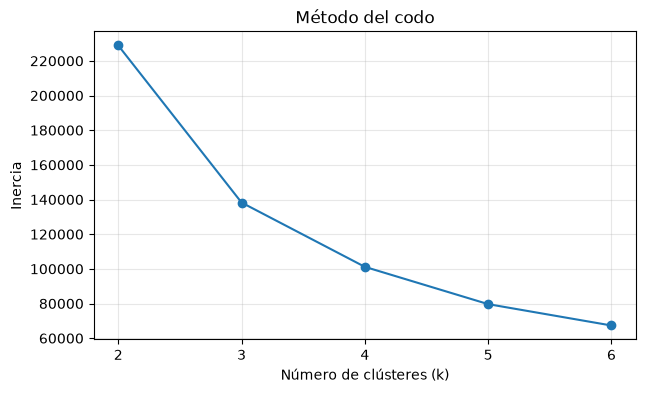

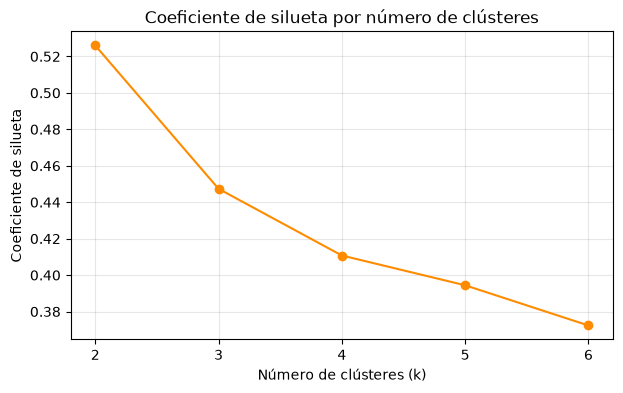

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

# 1-4. Ciclo de evaluación
for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_escalado)

    inercias.append(kmeans.inertia_)
    siluetas.append(
        silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42)
    )

# 5. Tabla comparativa
tabla_k = pd.DataFrame({
    "k": valores_k,
    "Inercia": inercias,
    "Silueta": siluetas
})
print(tabla_k)

# 6a. Método del codo
plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.show()

# 6b. Coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(valores_k, siluetas, marker="o", color="darkorange")
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

cluster
0     62496
1     95278
2    125763
Name: count, dtype: int64


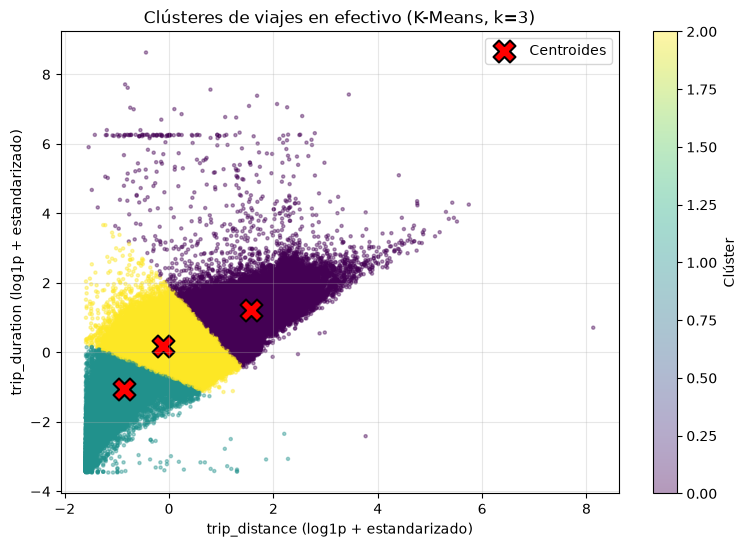

In [8]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Elección de k
k_final = 3

# 2-3. Modelo final y etiquetas
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = kmeans_final.fit_predict(X_escalado)

# Guardar etiquetas en df_cash (unidades originales) para interpretar los grupos
df_cash["cluster"] = etiquetas
print(df_cash["cluster"].value_counts().sort_index())

# 4-7. Gráfica de dispersión con centroides
plt.figure(figsize=(9, 6))
dispersion = plt.scatter(
    X_escalado[:, 0], X_escalado[:, 1],
    c=etiquetas, cmap="viridis", s=5, alpha=0.4
)

centroides = kmeans_final.cluster_centers_
plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=250, c="red", edgecolor="black", linewidth=1.5,
    label="Centroides"
)

plt.title(f"Clústeres de viajes en efectivo (K-Means, k={k_final})")
plt.xlabel("trip_distance (log1p + estandarizado)")
plt.ylabel("trip_duration (log1p + estandarizado)")
plt.legend()
plt.colorbar(dispersion, label="Clúster")
plt.grid(True, alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [9]:
# 1-2. DataFrame de resultados con las etiquetas del modelo final
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

# 3-4. Estadísticos por clúster en unidades originales (millas y minutos)
tabla_clusters = (
    df_resultado.groupby("cluster")
    .agg(
        viajes=("cluster", "count"),
        distancia_media=("trip_distance", "mean"),
        distancia_mediana=("trip_distance", "median"),
        duracion_media=("trip_duration", "mean"),
        duracion_mediana=("trip_duration", "median"),
    )
    .round(2)
)
print(tabla_clusters)

         viajes  distancia_media  distancia_mediana  duracion_media  \
cluster                                                               
0         62496            11.57               9.83           39.55   
1         95278             0.80               0.76            5.74   
2        125763             2.31               1.95           15.47   

         duracion_mediana  
cluster                    
0                   31.43  
1                    5.85  
2                   14.03  


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**
Elegí k = 3. La inercia bajó de 228,855 (k=2) a 138,246 (k=3), una caída de unas 90,600 unidades, la mayor de todo el análisis. Después las mejoras fueron menores: unas 37,100 de k=3 a k=4, unas 21,500 de k=4 a k=5 y unas 12,300 de k=5 a k=6. Ese cambio de pendiente en k=3 es el “codo”. La silueta es máxima en k=2 (0.526) y baja a 0.447 en k=3, 0.411 en k=4, 0.394 en k=5 y 0.372 en k=6. Aunque k=2 tiene mayor silueta, solo separaría viajes cortos de largos. Con k=3, la silueta sigue siendo aceptable y los grupos son más informativos, además de claros e interpretables: viajes cortos, medios y largos, con medias de distancia de 0.80, 2.31 y 11.57 millas. Por eso elegí k=3, que equilibra el codo, una silueta razonable y la interpretación de los grupos.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
- Clúster 1, “Viajes cortos”: 95,278 viajes. Distancia media de 0.80 mi (mediana 0.76) y duración media de 5.74 min (mediana 5.85). Son trayectos de pocas cuadras, de unos 6 minutos. Media y mediana casi coinciden, así que el grupo es homogéneo.
- Clúster 2, “Viajes urbanos medios”: 125,763 viajes. Distancia media de 2.31 mi (mediana 1.95) y duración media de 15.47 min (mediana 14.03). Es el viaje urbano típico de unos 15 minutos.
- Clúster 0, “Viajes largos”: 62,496 viajes. Distancia media de 11.57 mi (mediana 9.83) y duración media de 39.55 min (mediana 31.43). Son recorridos largos, por ejemplo hacia aeropuertos o entre distritos. La media es mayor que la mediana, lo que indica que algunos viajes muy largos elevan el promedio.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**
El clúster 0 tiene la mayor duración promedio (39.55 min). También tiene la mayor distancia promedio (11.57 mi), más que el clúster 2 (2.31 mi) y el clúster 1 (0.80 mi). Es decir, el grupo con los viajes más largos en tiempo también es el de los viajes más largos en distancia. Esto es lógico, porque a más distancia recorrida, normalmente se necesita más tiempo.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**
El grupo más numeroso es el clúster 2, con 125,763 viajes, casi el 44% de los 283,537 viajes en efectivo. Predominan los viajes de distancia corta a media, con media de 2.31 millas y mediana de 1.95, y de duración media, con 15.47 minutos de promedio y mediana de 14.03. Es el patrón de viaje urbano más común en este conjunto de datos. Como la media y la mediana son parecidas, el grupo es relativamente homogéneo.

Nota: las respuestas usan los números de tus salidas, así que no hace falta ejecutar nada más. Si tu clasificación de k=3 cambió, por ejemplo si reentrenaste el modelo, revisa que los números de clúster coincidan con los de tu tabla.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**